### Starting with parametric methods in pandas and scipy

#### Parametric Correlation Analysis (Pearson Method)

#### 1. What is Parametric Correlation Analysis?
* A statistical method used to measure the strength and direction of a relationship between two **linearly related, continuous numeric variables** (calculated through the **Pearson Method**).
* **Important Rule:** *Correlation does not imply causation!* Just because two variables move together does not mean one causes the other.

#### 2. Pearson Correlation Coefficient ($R$)
The Pearson correlation value ($R$) always falls between **$-1$ and $+1$**:
* **$R = 1$:** Strong **positive** linear relationship (both variables increase together).
* **$R = 0$:** **Not linearly correlated** (no straight-line relationship).
* **$R = -1$:** Strong **negative** linear relationship (as one variable increases, the other decreases).

#### 3. Pearson Correlation Assumptions
Pearson correlation assumes that:
1. Your data is **normally distributed**.
2. You have **continuous, numeric variables**.
3. Your variables are **linearly related**.

#### 4. Linear vs. Nonlinear Relationships
* **Linear Relationship:** Two variables change at a constant rate and form a **straight line** when plotted on a graph.
* **Nonlinear Relationship:** Two variables have a relationship that forms a **curve** (not a straight line) — for example, increasing up to a point and then dropping.
* **When to Use Pearson Correlation:**
  * Use it **to uncover linear relationships** between variables.
  * Do **not** use $R = 0$ to rule out possible **nonlinear relationships** (a curved relationship can still exist even when linear correlation is zero).





In [19]:
%pip install pandas numpy matplotlib seaborn scipy
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from pylab import rcParams

import scipy
from scipy.stats import pearsonr


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
%matplotlib inline
rcParams['figure.figsize'] = 8, 4
sns.set_style("whitegrid")

### The Pearson Correlation

In [21]:
# Import pandas library
import pandas as pd

# Load the mtcars dataset from the CSV file
cars = pd.read_csv('../../data/mtcars.csv')

# Rename columns and display the first 5 rows
cars.columns = ['car_names','mpg','cyl','disp', 'hp', 'drat', 'wt', 'qsec', 'vs', 'am', 'gear', 'carb']
cars.head(5)

,car_names,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


### Checking Model Assumptions Using Pairplots

#### 1. Satisfies Assumptions (Valid for Pearson Correlation)
* Variables like **`mpg`**, **`hp`**, **`qsec`**, and **`wt`** are **continuous numeric variables**.
* Their pairplot shows:
  * **Normally Distributed:** The diagonal histograms follow a bell-like shape.
  * **Linearly Related:** The scatter plots show points forming clear straight-line patterns.
* **Conclusion:** These variables are suitable for **Pearson $R$ correlation analysis** using `scipy`.



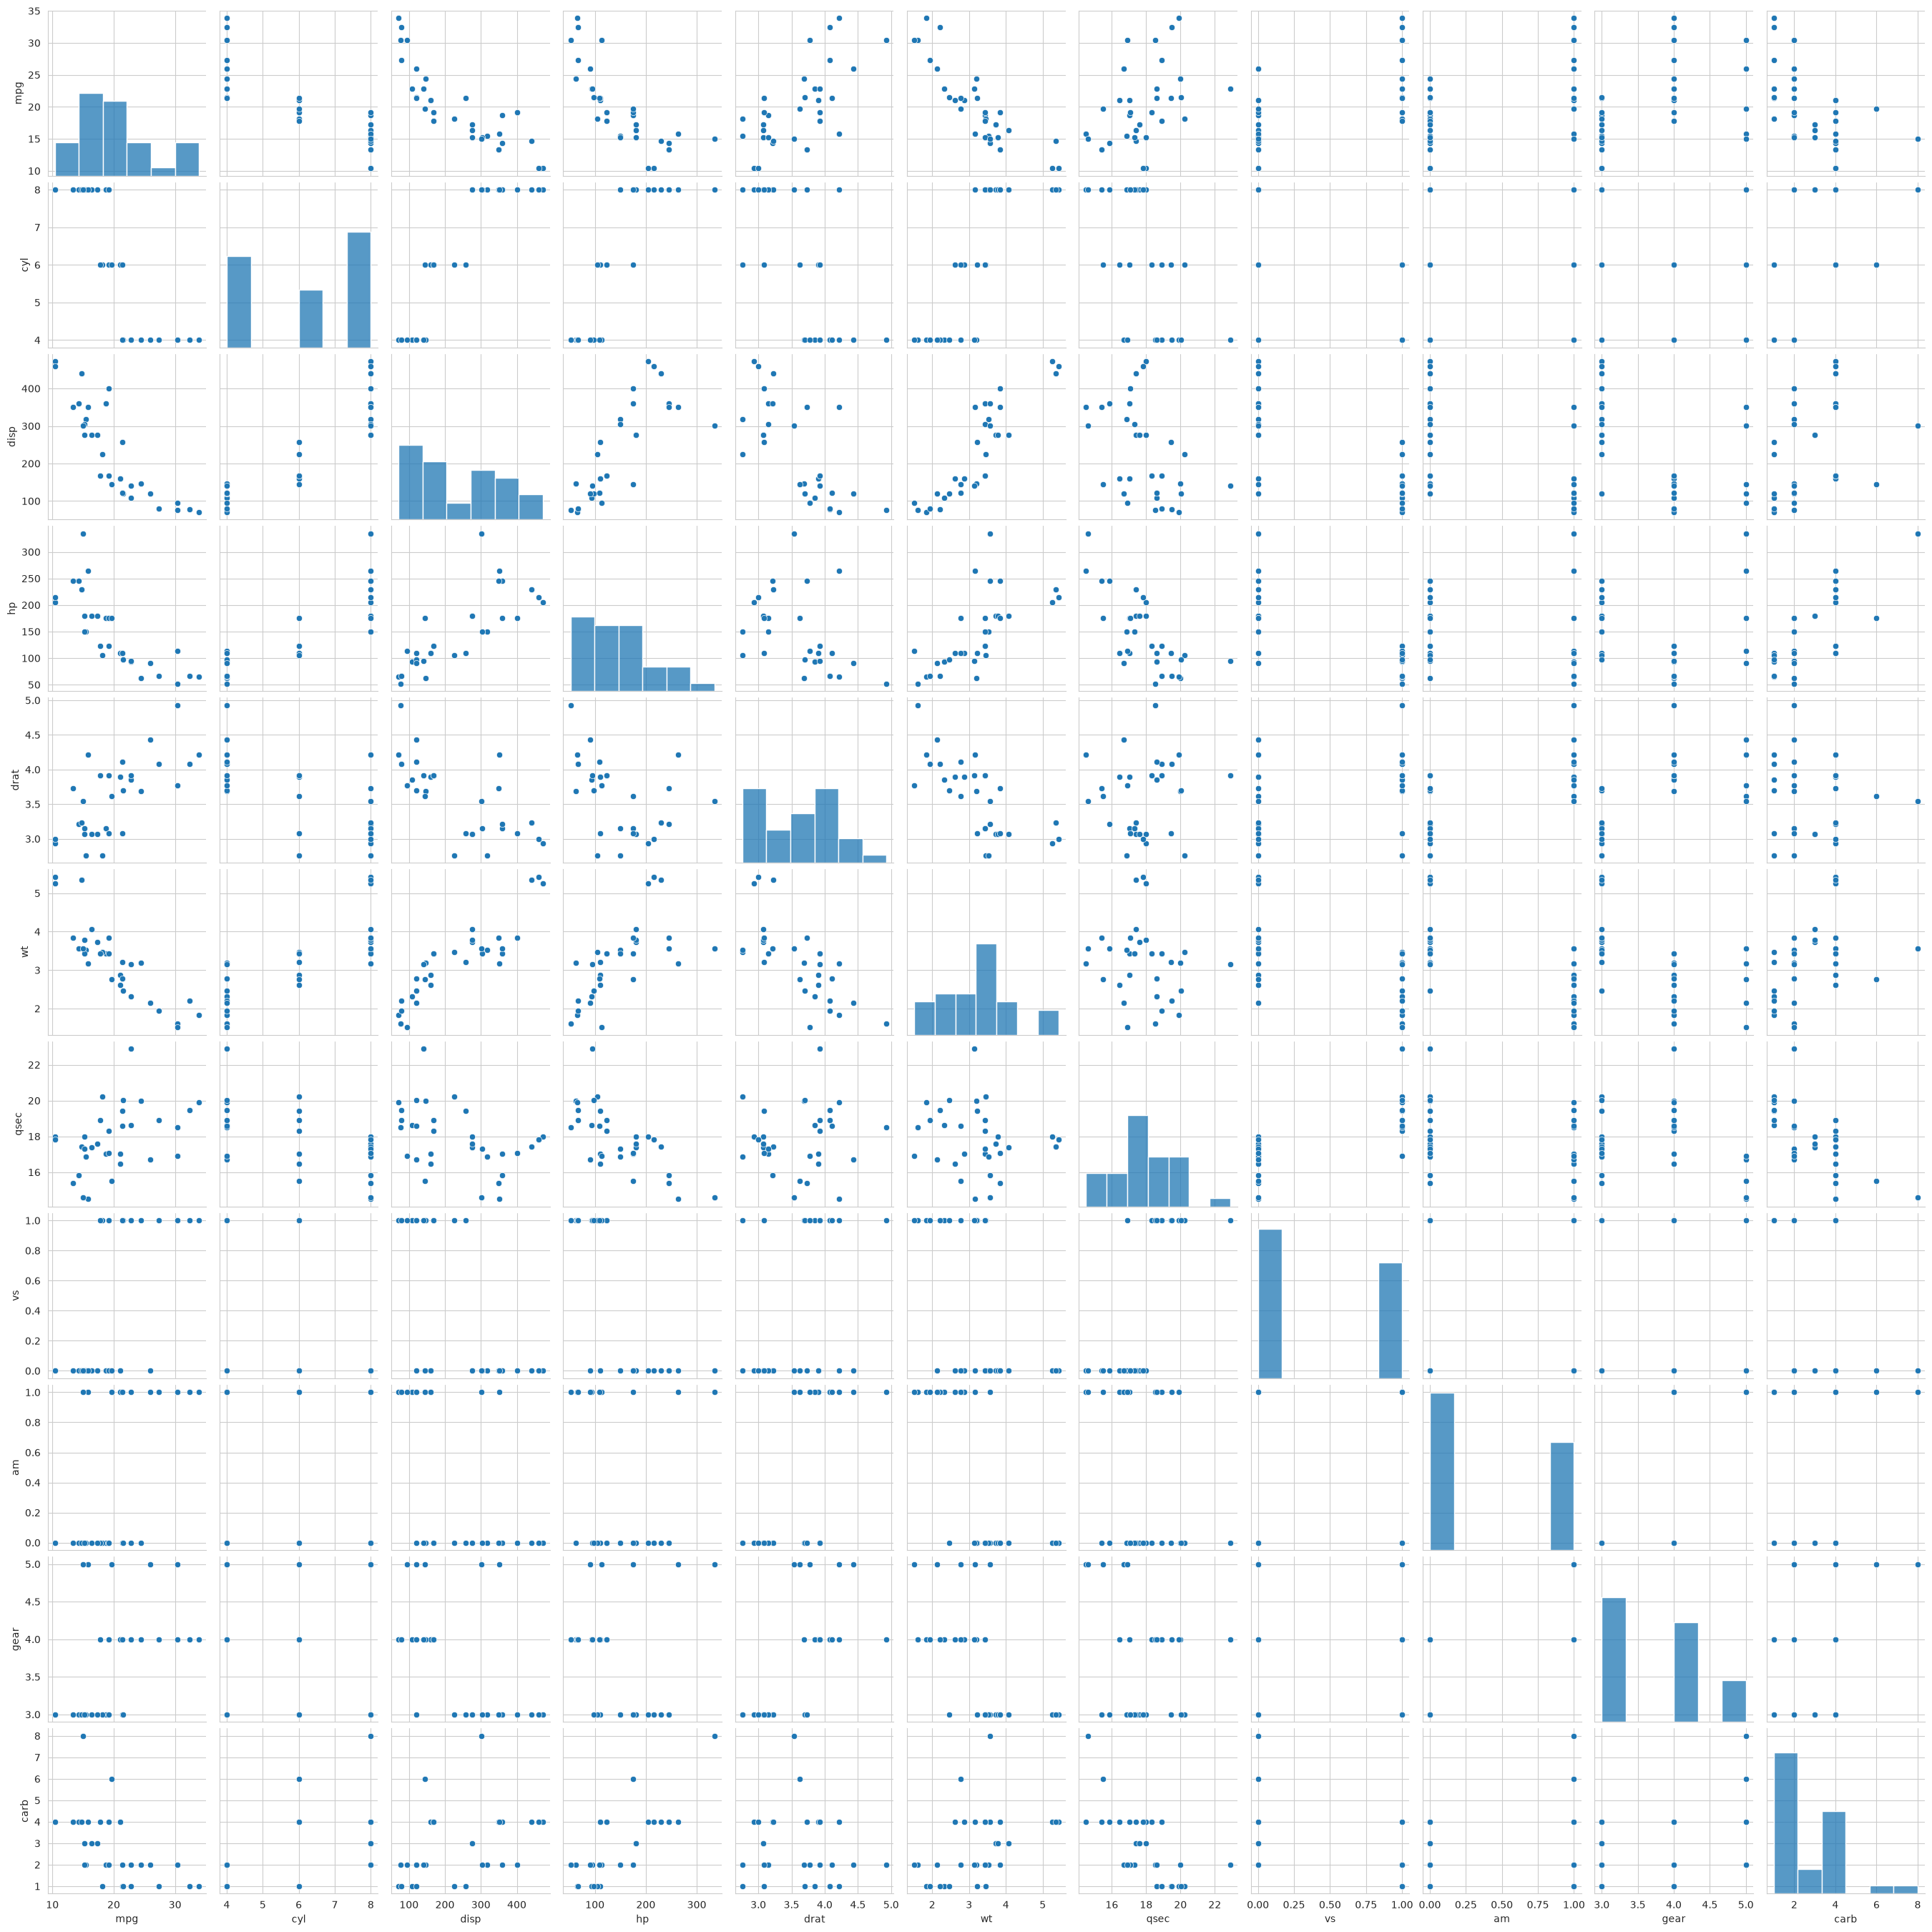

In [22]:
sns.pairplot(cars)

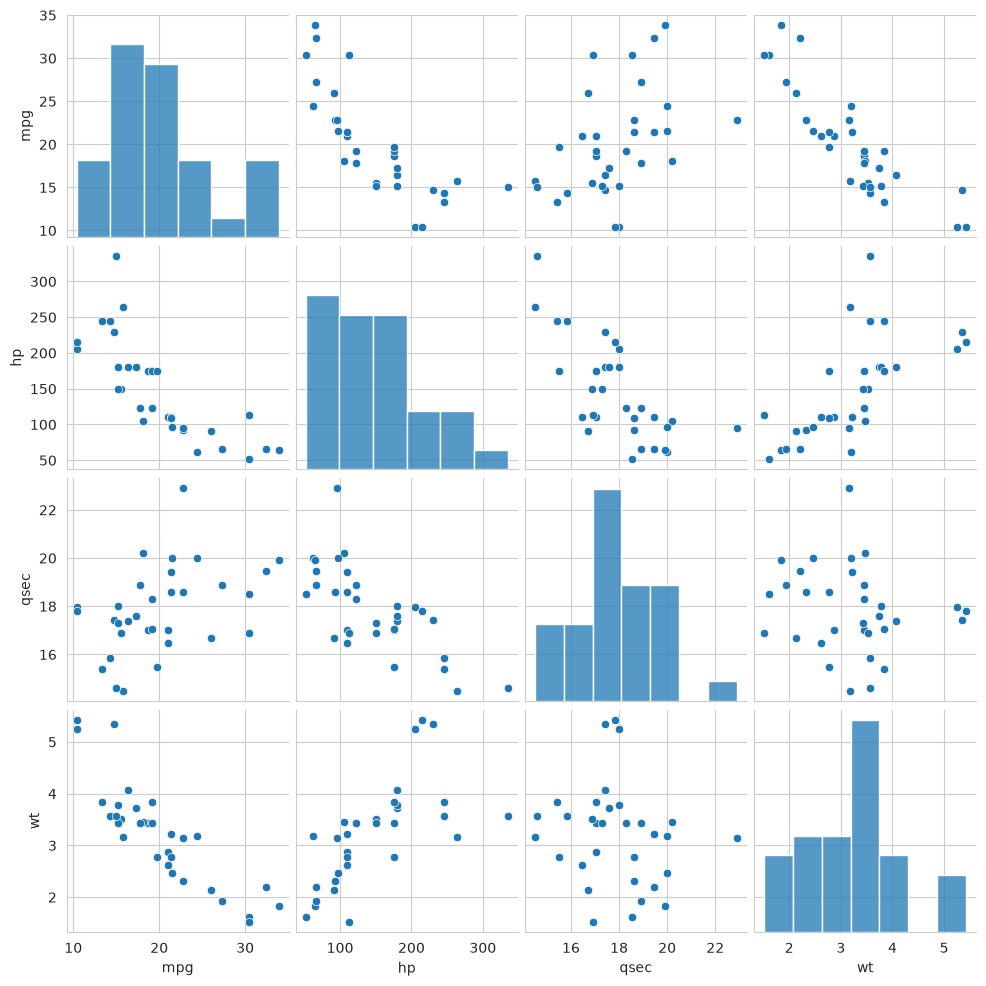

In [23]:
# Select the 4 continuous numeric columns ('mpg', 'hp', 'qsec', 'wt') from 'cars' and store in 'x'
x = cars[['mpg', 'hp', 'qsec', 'wt']]

# Create a pairplot to visually check linear relationships and distributions across all selected variables
sns.pairplot(x)

#### 2. Defies Assumptions (Not Valid for Pearson Correlation)
* Variables like **`gear`**, **`carb`**, and **`am`** are **categorical variables** (not continuous numbers):
  * **Multinomial Variable:** Has more than two fixed categories (e.g., `gear` has `3, 4, 5`).
  * **Binomial Variable:** Has only two fixed categories (e.g., `am` has `0` and `1`).
* Their plots show discrete vertical/horizontal lines of dots rather than a continuous linear trend.
* **Conclusion:** Do **not** use Pearson correlation on categorical variables.

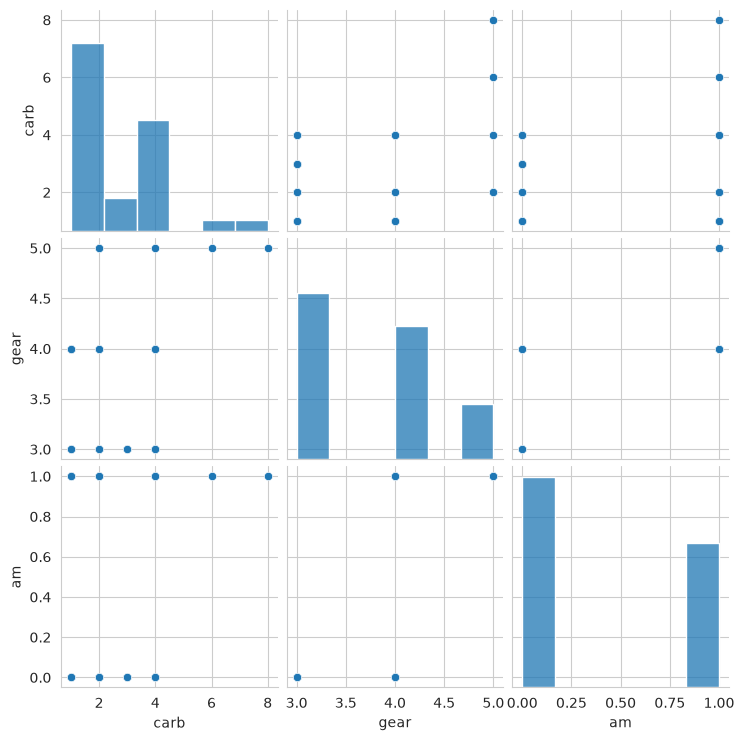

In [24]:
# Select the 3 categorical columns ('carb', 'gear', 'am') from 'cars' and store in 'x_cat'
x_cat = cars[['carb', 'gear', 'am']]

# Create a pairplot for categorical variables
# Output meaning:
# - The plot shows separate vertical/horizontal lines of dots and discrete bars instead of a smooth linear line
# - Because these are categorical variables (not continuous numeric variables), the Pearson correlation method cannot be applied to them
sns.pairplot(x_cat)

### Using scipy to calculate the Pearson correlation coefficient

### How Pearson Correlation ($R$) is Calculated

Behind the scenes, `pearsonr()` calculates $R$ in 4 simple steps:

1. **Find the Mean:** Calculate the average of both variables ($\bar{x}$ and $\bar{y}$).
2. **Measure Deviations:** Find how far each value is from its own average ($x_i - \bar{x}$ and $y_i - \bar{y}$).
3. **Multiply Deviations:** Multiply the two differences together for each row (opposite directions give a negative value).
4. **Standardize (Divide):** Divide by the total spread of both variables so the final result always stays between **$-1$ and $+1$**.

$$R = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$

In [25]:
# Extract 'mpg', 'hp', 'qsec', and 'wt' columns into separate variables
mpg = cars['mpg']
hp = cars['hp']
qsec = cars['qsec']
wt = cars['wt']

# Calculate Pearson correlation coefficient (R) and p-value between 'mpg' and 'hp'
pearsonr_coefficient, p_value = pearsonr(mpg, hp)

# Print correlation rounded to 3 decimal places using modern f-string (Output: -0.776, strong negative relationship)
print(f'PearsonR Correlation Coefficient {pearsonr_coefficient:.3f}')

PearsonR Correlation Coefficient -0.776


In [26]:
# Calculate Pearson correlation coefficient (R) and p-value between 'mpg' and 'qsec'
pearsonr_coefficient, p_value = pearsonr(mpg, qsec)

# Print correlation rounded to 3 decimal places (Output: 0.419, moderate positive relationship)
print(f'PearsonR Correlation Coefficient {pearsonr_coefficient:.3f}')

PearsonR Correlation Coefficient 0.419


In [27]:
# Calculate Pearson correlation coefficient (R) and p-value between 'mpg' and 'wt'
pearsonr_coefficient, p_value = pearsonr(mpg, wt)

# Print correlation rounded to 3 decimal places (Output: -0.868, very strong negative relationship — heavier cars have lower mpg)
print(f'PearsonR Correlation Coefficient {pearsonr_coefficient:.3f}')

PearsonR Correlation Coefficient -0.868


### Using Pandas to Calculate the Pearson Correlation Coefficient

* **`df.corr()`** is a built-in Pandas method that calculates the **Pearson correlation coefficient ($R$)** for **all pairs of numeric columns** in a DataFrame at once.
* Instead of checking two variables one by one with `scipy`, `.corr()` generates a complete **correlation matrix table**.
* The diagonal values are always **`1.0`** because every variable has a perfect positive correlation with itself.

In [28]:
# Calculate the Pearson correlation matrix for all continuous numeric columns in 'x' at once
corr = x.corr()

# Display the correlation matrix table (diagonal values = 1.0, values closer to 1 or -1 show strong relationships)
corr

,mpg,hp,qsec,wt
mpg,1.000000,-0.776168,0.418684,-0.867659
hp,-0.776168,1.000000,-0.708223,0.658748
qsec,0.418684,-0.708223,1.000000,-0.174716
wt,-0.867659,0.658748,-0.174716,1.000000


### Using Seaborn to Visualize the Pearson Correlation Coefficient

* **`sns.heatmap()`** turns the numeric correlation matrix (`corr`) into a **color-coded grid (heatmap)**, making it easy to spot strong and weak relationships at a glance.
* **`xticklabels` & `yticklabels`:** Label the horizontal and vertical axes with the column names (`mpg`, `hp`, `qsec`, `wt`).
* **How to Read the Colors:**
  * **Light Cream / Peach (closer to `+1.0`):** Strong **positive** linear relationship (e.g., the diagonal `1.0` boxes, or `hp` vs. `wt`).
  * **Dark Black / Deep Purple (closer to `-1.0`):** Strong **negative** linear relationship (e.g., `mpg` vs. `wt` and `mpg` vs. `hp`).
  * **Red / Magenta (near `0.0`):** Weak or no linear relationship.

<Axes: >

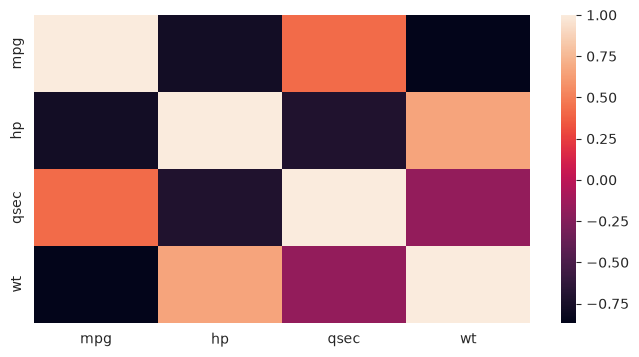

In [29]:
# Plot a color-coded heatmap of the correlation matrix with column names on both axes
# Output meaning: Light cream/orange boxes show strong positive correlation (+1), while dark black boxes show strong negative correlation (-1)
sns.heatmap(corr, xticklabels=corr.columns.values, yticklabels=corr.columns.values)